# Finite-thickness geometry tests

This calculation tests whether the gravity-driven passive-sliding fold found in the circular cap persists when the ice has nonzero thickness at the model boundaries. It also tests a distinct flat-bed geometry in which the relief is confined to the free surface.

## Model, units, and boundary conditions

The model is two-dimensional, incompressible Newtonian ice with density 917 kg m$^{-3}$ and viscosity $2.5\times10^8$ Pa yr. Gravity acts at a mean surface slope of 0.05 rad. The upper boundary is traction free. The bed is impermeable and obeys the passive law $u_t=C\tau_b$, with $C=10^{-5}$ m yr$^{-1}$ Pa$^{-1}$. No ice velocity is prescribed. Surface mass balance is diagnosed from the steady kinematic condition.

The bed-trough domains are periodic and retain 10--50 m of ice outside the relief, so they contain neither a lateral wall nor a zero-thickness margin. The surface-depression case has a flat bed. The observational prediction is an overturned limb if the material-map Jacobian $J=\left.\partial x/\partial x_0\right|_\tau$ reaches zero before surface re-emergence.

## Calculation and interpretation

The calculation reports the minimum $J$, the age at which it occurs, the minimum horizontal speed, the power balance, and the no-penetration residual. The closest case is repeated on three meshes. A positive $J$ is a calculated negative result for the stated geometry. It does not imply a general no-folding condition for finite-thickness glaciers.

Solving broad overdeepening.


{'geometry': 'broad overdeepening', 'mesh': '72 x 18', 'minimum thickness (m)': 50.0, 'maximum thickness (m)': 200.0, 'minimum grid u (m/yr)': np.float64(0.00021371418881033265), 'minimum path u (m/yr)': np.float64(0.005287576399373569), 'minimum J': np.float64(0.7418359718760095), 'age of minimum J (yr)': np.float64(38655.0), 'accumulation min (m/yr)': np.float64(3.2637796426664634e-05), 'accumulation max (m/yr)': np.float64(0.004695117431290689), 'cells': 2592, 'basal dissipation / gravity power': np.float64(7.618857978578223e-05), 'relative energy residual': np.float64(0.006736005503665117), 'rms basal normal speed': np.float64(1.5921198697993256e-07)}


Solving U-shaped overdeepening, 10 m margin.


{'geometry': 'U-shaped overdeepening, 10 m margin', 'mesh': '72 x 18', 'minimum thickness (m)': 10.0, 'maximum thickness (m)': 160.0, 'minimum grid u (m/yr)': np.float64(0.00012483303147142055), 'minimum path u (m/yr)': np.float64(0.0006908221640456276), 'minimum J': np.float64(0.554236835710805), 'age of minimum J (yr)': np.float64(25760.0), 'accumulation min (m/yr)': np.float64(7.185215769050242e-06), 'accumulation max (m/yr)': np.float64(0.005358103214140836), 'cells': 2592, 'basal dissipation / gravity power': np.float64(0.008875845811969364), 'relative energy residual': np.float64(0.01911496504991176), 'rms basal normal speed': np.float64(2.0849648835129692e-07)}


Solving U-shaped overdeepening, 25 m margin.


{'geometry': 'U-shaped overdeepening, 25 m margin', 'mesh': '72 x 18', 'minimum thickness (m)': 25.0, 'maximum thickness (m)': 175.0, 'minimum grid u (m/yr)': np.float64(0.0001330732895991792), 'minimum path u (m/yr)': np.float64(0.0024029060019857785), 'minimum J': np.float64(0.5117570179456741), 'age of minimum J (yr)': np.float64(21745.0), 'accumulation min (m/yr)': np.float64(1.6474508279142908e-05), 'accumulation max (m/yr)': np.float64(0.006012655639648978), 'cells': 2592, 'basal dissipation / gravity power': np.float64(0.013447073239194012), 'relative energy residual': np.float64(0.02166463458753925), 'rms basal normal speed': np.float64(2.570855284056947e-07)}


... (2 outputs left out)

,geometry,mesh,minimum thickness (m),maximum thickness (m),minimum grid u (m/yr),minimum path u (m/yr),minimum J,age of minimum J (yr),accumulation min (m/yr),accumulation max (m/yr),cells,basal dissipation / gravity power,relative energy residual,rms basal normal speed
0,broad overdeepening,72 x 18,50,200,0.000213714,0.00528758,0.741836,38655,3.26378e-05,0.00469512,2592,7.61886e-05,0.00673601,1.59212e-07
1,"U-shaped overdeepening, 10 m margin",72 x 18,10,160,0.000124833,0.000690822,0.554237,25760,7.18522e-06,0.0053581,2592,0.00887585,0.019115,2.08496e-07
2,"U-shaped overdeepening, 25 m margin",72 x 18,25,175,0.000133073,0.00240291,0.511757,21745,1.64745e-05,0.00601266,2592,0.0134471,0.0216646,2.57086e-07
3,surface depression,72 x 18,40,170,0.383957,0.392808,0.862738,400,4.42726e-05,0.243913,2592,0.538747,-1.42808e-11,3.94539e-12


Checking U-shaped overdeepening on a 108 x 27 mesh.


Checking U-shaped overdeepening on a 144 x 36 mesh.


,mesh,cells,minimum J,age of minimum J (yr),minimum path u (m/yr),rms basal normal speed,relative energy residual
0,72 x 18,2592,0.511757,21745,0.00240291,2.57086e-07,0.0216646
1,108 x 27,5832,0.530671,20550,0.00237625,2.04439e-07,0.0209713
2,144 x 36,10368,0.520836,21010,0.00233935,1.64273e-07,0.0187074


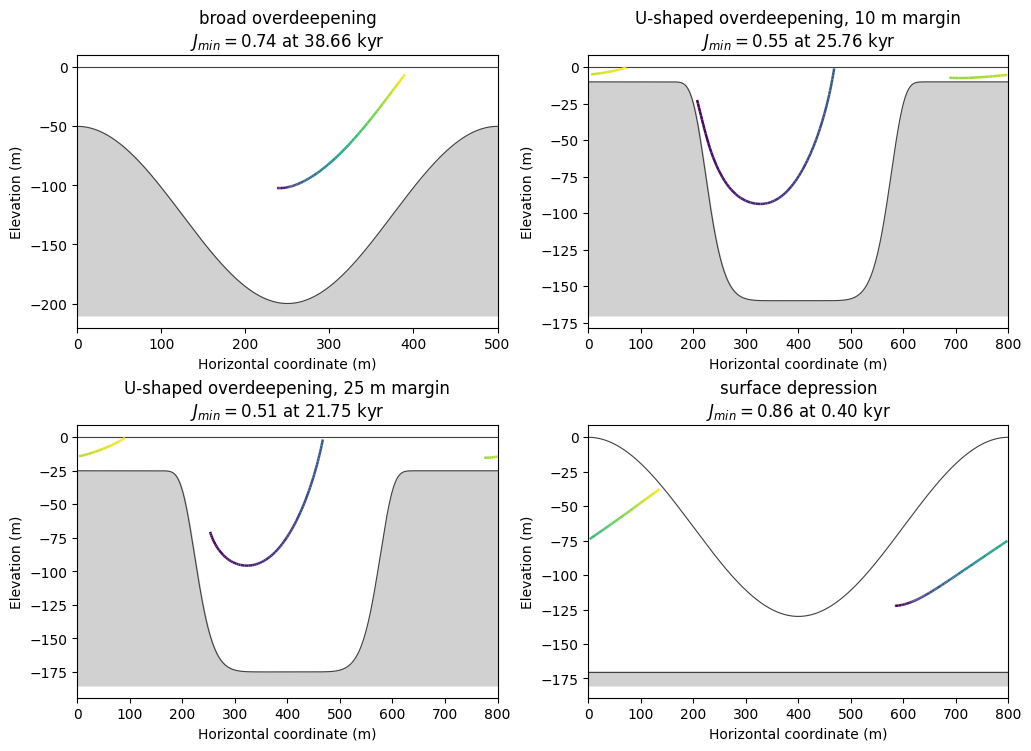

In [1]:
%matplotlib inline
"""Test steady overturning in smooth, finite-thickness glacier geometries."""

from pathlib import Path
import logging
import warnings

warnings.filterwarnings("ignore", message="Unable to import recommended hash")
warnings.filterwarnings("ignore", message="The .*Function.at.* method")
logging.getLogger("tsfc").setLevel(logging.ERROR)

import firedrake as fd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.interpolate import RegularGridInterpolator

plt.rcParams["ps.fonttype"] = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")


DENSITY = 917.0  # kg m^-3
GRAVITY = 9.81  # m s^-2
VISCOSITY = 2.5e8  # Pa yr
SURFACE_SLOPE = 0.05  # rad
BASAL_DRAG = 1.0e5  # Pa yr m^-1
NITSCHE_PENALTY = 3.0e6

GEOMETRIES = [
    {
        "name": "broad overdeepening",
        "kind": "bed trough",
        "length": 500.0,
        "background thickness": 50.0,
        "relief": 150.0,
    },
    {
        "name": "U-shaped overdeepening, 10 m margin",
        "kind": "bed trough",
        "length": 800.0,
        "shape scale": 180.0,
        "shape exponent": 8.0,
        "background thickness": 10.0,
        "relief": 150.0,
    },
    {
        "name": "U-shaped overdeepening, 25 m margin",
        "kind": "bed trough",
        "length": 800.0,
        "shape scale": 180.0,
        "shape exponent": 8.0,
        "background thickness": 25.0,
        "relief": 150.0,
    },
    {
        "name": "surface depression",
        "kind": "surface depression",
        "length": 800.0,
        "background thickness": 170.0,
        "relief": 130.0,
    },
]

CONVERGENCE_MESHES = [(72, 18), (108, 27), (144, 36)]

SOLVER_PARAMETERS = {
    "ksp_type": "preonly",
    "pc_type": "lu",
    "pc_factor_mat_solver_type": "mumps",
}


def geometry_shape(x, geometry):
    """One smooth feature per periodic model length."""
    length = geometry["length"]
    distance = (np.asarray(x) - 0.5 * length + 0.5 * length) % length - 0.5 * length
    if "shape exponent" in geometry:
        return np.exp(
            -(np.abs(distance) / geometry["shape scale"]) ** geometry["shape exponent"]
        )
    if "half width" not in geometry:
        return 0.5 * (1.0 + np.cos(2.0 * np.pi * distance / length))
    half_width = geometry["half width"]
    shape = np.zeros_like(distance, dtype=float)
    inside = np.abs(distance) < half_width
    shape[inside] = 0.5 * (1.0 + np.cos(np.pi * distance[inside] / half_width))
    return shape


def geometry_shape_slope(x, geometry):
    """Derivative of the periodic shape."""
    length = geometry["length"]
    distance = (np.asarray(x) - 0.5 * length + 0.5 * length) % length - 0.5 * length
    if "shape exponent" in geometry:
        exponent = geometry["shape exponent"]
        scale = geometry["shape scale"]
        shape = np.exp(-(np.abs(distance) / scale) ** exponent)
        return -shape * exponent * np.abs(distance) ** (exponent - 1.0) * np.sign(distance) / scale**exponent
    if "half width" not in geometry:
        return -np.pi / length * np.sin(2.0 * np.pi * distance / length)
    half_width = geometry["half width"]
    slope = np.zeros_like(distance, dtype=float)
    inside = np.abs(distance) < half_width
    slope[inside] = -0.5 * np.pi / half_width * np.sin(
        np.pi * distance[inside] / half_width
    )
    return slope


def surfaces(x, geometry):
    """Return bed and surface elevations in metres."""
    shape = geometry_shape(x, geometry)
    thickness = geometry["background thickness"]
    relief = geometry["relief"]
    if geometry["kind"] == "bed trough":
        bed = -thickness - relief * shape
        surface = np.zeros_like(shape)
    elif geometry["kind"] == "surface depression":
        bed = np.full_like(shape, -thickness)
        surface = -relief * shape
    else:
        raise ValueError(f"Unknown geometry {geometry['kind']}")
    return bed, surface


def surface_slope(x, geometry):
    if geometry["kind"] == "surface depression":
        return -geometry["relief"] * geometry_shape_slope(x, geometry)
    return np.zeros_like(np.asarray(x), dtype=float)


def make_mesh(geometry, nx, nz):
    """Map a periodic rectangle into the prescribed smooth geometry."""
    length = geometry["length"]
    mesh = fd.PeriodicRectangleMesh(nx, nz, length, 1.0, direction="x")
    reference = mesh.coordinates.dat.data_ro.copy()
    bed, surface = surfaces(reference[:, 0], geometry)
    mesh.coordinates.dat.data[:, 1] = bed + reference[:, 1] * (surface - bed)
    mesh.clear_spatial_index()
    return mesh


def solve_stokes(geometry, nx=72, nz=18):
    """Solve full Stokes flow with no penetration and linear basal drag."""
    mesh = make_mesh(geometry, nx, nz)
    velocity_space = fd.VectorFunctionSpace(mesh, "CG", 2)
    pressure_space = fd.FunctionSpace(mesh, "CG", 1)
    mixed_space = velocity_space * pressure_space
    solution = fd.Function(mixed_space)
    u, p = fd.split(solution)
    v, q = fd.TestFunctions(mixed_space)
    strain = fd.sym(fd.grad(u))
    body_force = fd.Constant(
        (
            DENSITY * GRAVITY * np.sin(SURFACE_SLOPE),
            -DENSITY * GRAVITY * np.cos(SURFACE_SLOPE),
        )
    )
    residual = (
        2.0 * VISCOSITY * fd.inner(strain, fd.sym(fd.grad(v)))
        - p * fd.div(v)
        - q * fd.div(u)
        - fd.dot(body_force, v)
    ) * fd.dx

    normal = fd.FacetNormal(mesh)
    tangent = fd.as_vector((-normal[1], normal[0]))
    identity = fd.Identity(2)
    stress = 2.0 * VISCOSITY * fd.sym(fd.grad(u)) - p * identity
    test_stress = 2.0 * VISCOSITY * fd.sym(fd.grad(v)) - q * identity
    normal_speed = fd.dot(u, normal)
    test_normal_speed = fd.dot(v, normal)
    residual += (
        BASAL_DRAG * fd.dot(u, tangent) * fd.dot(v, tangent)
        - fd.dot(stress * normal, normal) * test_normal_speed
        - fd.dot(test_stress * normal, normal) * normal_speed
        + NITSCHE_PENALTY
        * VISCOSITY
        / fd.CellDiameter(mesh)
        * normal_speed
        * test_normal_speed
    ) * fd.ds(1)

    fd.solve(residual == 0, solution, solver_parameters=SOLVER_PARAMETERS)
    velocity, pressure = solution.subfunctions
    bed_length = fd.assemble(fd.Constant(1.0) * fd.ds(1, domain=mesh))
    basal_speed = fd.dot(velocity, tangent)
    gravity_power = fd.assemble(fd.dot(body_force, velocity) * fd.dx)
    basal_dissipation = fd.assemble(BASAL_DRAG * basal_speed**2 * fd.ds(1))
    viscous_dissipation = fd.assemble(
        2.0
        * VISCOSITY
        * fd.inner(fd.sym(fd.grad(velocity)), fd.sym(fd.grad(velocity)))
        * fd.dx
    )
    diagnostics = {
        "cells": mesh.num_cells(),
        "basal dissipation / gravity power": basal_dissipation / gravity_power,
        "relative energy residual": (
            gravity_power - basal_dissipation - viscous_dissipation
        )
        / gravity_power,
        "rms basal normal speed": np.sqrt(
            fd.assemble(fd.dot(velocity, normal) ** 2 * fd.ds(1)) / bed_length
        ),
    }
    return mesh, velocity, diagnostics


def make_sampler(geometry, velocity, nx=361, nz=121):
    """Resample the finite-element velocity in terrain-following coordinates."""
    length = geometry["length"]
    spacing = length / nx
    x = (np.arange(nx) + 0.5) * spacing
    sigma = np.linspace(0.03, 0.995, nz)
    bed, surface = surfaces(x, geometry)
    X = np.tile(x, (nz, 1))
    Z = bed[None, :] + sigma[:, None] * (surface - bed)[None, :]
    points = np.column_stack((X.ravel(), Z.ravel()))
    values = np.asarray(velocity.at(points, tolerance=1.0e-7)).reshape(Z.shape + (2,))
    fields = {}
    for component, name in enumerate(("u", "w")):
        periodic_values = np.column_stack(
            (values[:, -1, component], values[..., component], values[:, 0, component])
        )
        fields[name] = RegularGridInterpolator(
            (sigma, np.r_[x[-1] - length, x, x[0] + length]),
            periodic_values,
            bounds_error=False,
            fill_value=np.nan,
        )

    def sample(name, x_value, z_value):
        x_values, z_values = np.broadcast_arrays(x_value, z_value)
        wrapped = np.mod(x_values, length)
        bed_values, surface_values = surfaces(wrapped, geometry)
        sigma_values = (z_values - bed_values) / (surface_values - bed_values)
        points = np.column_stack((sigma_values.ravel(), wrapped.ravel()))
        result = fields[name](points).reshape(x_values.shape)
        return float(result) if result.ndim == 0 else result

    return sample, (np.nanmin(values[..., 0]), np.nanmax(values[..., 0]))


def trace_material_map(geometry, sample, maximum_age=100_000.0, time_step=5.0, count=401):
    """Trace surface origins and retain the most strongly overturned isochrone."""
    length = geometry["length"]
    sources = np.linspace(0.0, length, count, endpoint=False)
    bed, surface = surfaces(sources, geometry)
    depth = 0.005 * (surface - bed)
    start_z = surface - depth
    surface_u = sample("u", sources, start_z)
    surface_w = sample("w", sources, start_z)
    accumulation = surface_u * surface_slope(sources, geometry) - surface_w
    keep = accumulation > 1.0e-6
    sources = sources[keep]
    state = np.column_stack((sources, start_z[keep]))

    def velocity(values):
        return np.column_stack(
            (sample("u", values[:, 0], values[:, 1]), sample("w", values[:, 0], values[:, 1]))
        )

    best = {
        "minimum J": np.inf,
        "age": np.nan,
        "sources": None,
        "states": None,
        "jacobian": None,
        "valid": None,
    }
    minimum_path_speed = np.inf
    ages = np.arange(0.0, maximum_age + time_step, time_step)
    for step_index, age in enumerate(ages):
        local_bed, local_surface = surfaces(state[:, 0], geometry)
        sigma = (state[:, 1] - local_bed) / (local_surface - local_bed)
        valid = np.isfinite(state[:, 0]) & (sigma > 0.032) & (sigma < 0.996)
        valid_indices = np.where(valid)[0]
        groups = np.split(valid_indices, np.where(np.diff(valid_indices) > 1)[0] + 1)
        jacobian = np.full(len(sources), np.nan)
        for group in groups:
            if len(group) >= 5:
                jacobian[group] = np.gradient(state[group, 0], sources[group])
        if np.any(np.isfinite(jacobian)):
            minimum = np.nanmin(jacobian)
            if minimum < best["minimum J"]:
                best = {
                    "minimum J": minimum,
                    "age": age,
                    "sources": sources.copy(),
                    "states": state.copy(),
                    "jacobian": jacobian.copy(),
                    "valid": valid.copy(),
                }
        if step_index == len(ages) - 1 or not np.any(valid):
            break
        k1 = velocity(state)
        minimum_path_speed = min(minimum_path_speed, np.nanmin(k1[valid, 0]))
        k2 = velocity(state + 0.5 * time_step * k1)
        k3 = velocity(state + 0.5 * time_step * k2)
        k4 = velocity(state + time_step * k3)
        state += time_step * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0
    best["minimum path speed"] = minimum_path_speed
    best["accumulation range"] = (
        np.min(accumulation[keep]),
        np.max(accumulation[keep]),
    )
    return best


def run_case(geometry, nx, nz):
    """Solve one geometry and trace its surface-deposition map."""
    _, velocity, diagnostics = solve_stokes(geometry, nx, nz)
    sample, horizontal_speed_range = make_sampler(geometry, velocity)
    material_map = trace_material_map(geometry, sample)
    minimum_thickness = geometry["background thickness"]
    maximum_thickness = minimum_thickness
    if geometry["kind"] == "bed trough":
        maximum_thickness += geometry["relief"]
    else:
        minimum_thickness -= geometry["relief"]
    row = {
        "geometry": geometry["name"],
        "mesh": f"{nx} x {nz}",
        "minimum thickness (m)": minimum_thickness,
        "maximum thickness (m)": maximum_thickness,
        "minimum grid u (m/yr)": horizontal_speed_range[0],
        "minimum path u (m/yr)": material_map["minimum path speed"],
        "minimum J": material_map["minimum J"],
        "age of minimum J (yr)": material_map["age"],
        "accumulation min (m/yr)": material_map["accumulation range"][0],
        "accumulation max (m/yr)": material_map["accumulation range"][1],
    } | diagnostics
    return row, material_map


results = []
saved_cases = {}
for geometry in GEOMETRIES:
    print(f"Solving {geometry['name']}.", flush=True)
    row, material_map = run_case(geometry, *CONVERGENCE_MESHES[0])
    results.append(row)
    print(row, flush=True)
    saved_cases[geometry["name"]] = (geometry, material_map)

results = pd.DataFrame(results)
display(results)

reference_geometry = next(
    geometry
    for geometry in GEOMETRIES
    if geometry["name"] == "U-shaped overdeepening, 25 m margin"
)
convergence_rows = []
for nx, nz in CONVERGENCE_MESHES:
    if (nx, nz) == CONVERGENCE_MESHES[0]:
        convergence_rows.append(
            results[
                results["geometry"] == "U-shaped overdeepening, 25 m margin"
            ].iloc[0].to_dict()
        )
        continue
    print(f"Checking U-shaped overdeepening on a {nx} x {nz} mesh.", flush=True)
    row, _ = run_case(reference_geometry, nx, nz)
    convergence_rows.append(row)
convergence = pd.DataFrame(convergence_rows)
display(
    convergence[
        [
            "mesh",
            "cells",
            "minimum J",
            "age of minimum J (yr)",
            "minimum path u (m/yr)",
            "rms basal normal speed",
            "relative energy residual",
        ]
    ]
)

figure, axes = plt.subplots(2, 2, figsize=(10.2, 7.4), constrained_layout=True)
selected = [
    "broad overdeepening",
    "U-shaped overdeepening, 10 m margin",
    "U-shaped overdeepening, 25 m margin",
    "surface depression",
]
for axis, case_name in zip(axes.ravel(), selected):
    geometry, material_map = saved_cases[case_name]
    length = geometry["length"]
    x = np.linspace(0.0, length, 601)
    bed, surface = surfaces(x, geometry)
    axis.fill_between(x, bed, np.min(bed) - 10.0, color="0.82")
    axis.plot(x, bed, color="0.25", linewidth=0.8)
    axis.plot(x, surface, color="0.25", linewidth=0.8)
    states = material_map["states"]
    valid = material_map["valid"] & np.isfinite(material_map["jacobian"])
    plot_points = states[valid].copy()
    plot_points[:, 0] = np.mod(plot_points[:, 0], length)
    order = np.argsort(plot_points[:, 0])
    plot_points = plot_points[order]
    plot_sources = material_map["sources"][valid][order]
    neighboring = np.diff(plot_points[:, 0]) < 0.05 * length
    segments = np.stack((plot_points[:-1], plot_points[1:]), axis=1)[neighboring]
    collection = LineCollection(segments, cmap="viridis", linewidth=1.8)
    collection.set_array(
        (0.5 * (plot_sources[:-1] + plot_sources[1:]))[neighboring]
    )
    axis.add_collection(collection)
    axis.set(
        xlim=(0.0, length),
        xlabel="Horizontal coordinate (m)",
        ylabel="Elevation (m)",
        title=(
            f"{case_name}\n"
            f"$J_{{min}}={material_map['minimum J']:.2f}$ at "
            f"{material_map['age'] / 1000:.2f} kyr"
        ),
    )

figure_directory = Path("../figures")
for suffix in ("eps", "pdf"):
    figure.savefig(figure_directory / f"dissipative_sliding_geometry_survey.{suffix}")
figure.savefig(figure_directory / "dissipative_sliding_geometry_survey.png", dpi=220)
for suffix in ("eps", "pdf"):
    figure.savefig(figure_directory / f"Figure8.{suffix}")
figure.savefig(figure_directory / "Figure8.png", dpi=220)
plt.show()
